In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


# AgriVision: Notebook 1 - Data Exploration and Preprocessing


In [2]:
import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

print("Libraries loaded")

Libraries loaded


In [4]:
import os
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path(r"D:\AgriVision\data\raw")

rows = []
for img in DATA_DIR.rglob("*"):
    if img.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        label = re.sub(r"\d+$", "", img.stem)
        rows.append({"path": str(img), "label": label})

df = pd.DataFrame(rows)
print(len(df), "images")
print(df["label"].value_counts())

999 images
label
Septoria      349
YellowRust    239
Mildew        161
BrownRust     128
Healthy       122
Name: count, dtype: int64


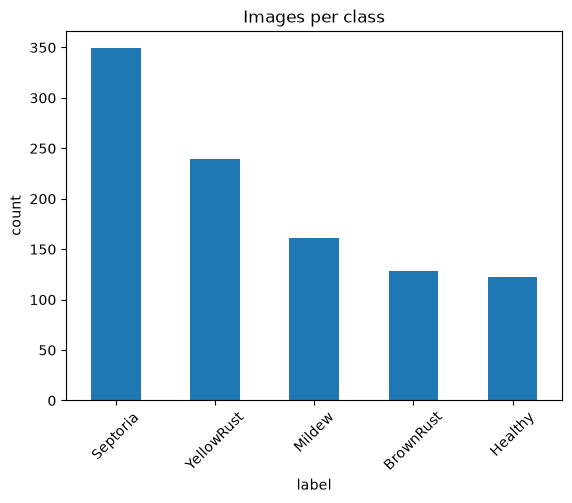

In [5]:
df["label"].value_counts().plot(kind="bar", title="Images per class")
plt.ylabel("count")
plt.xticks(rotation=45)
plt.show()

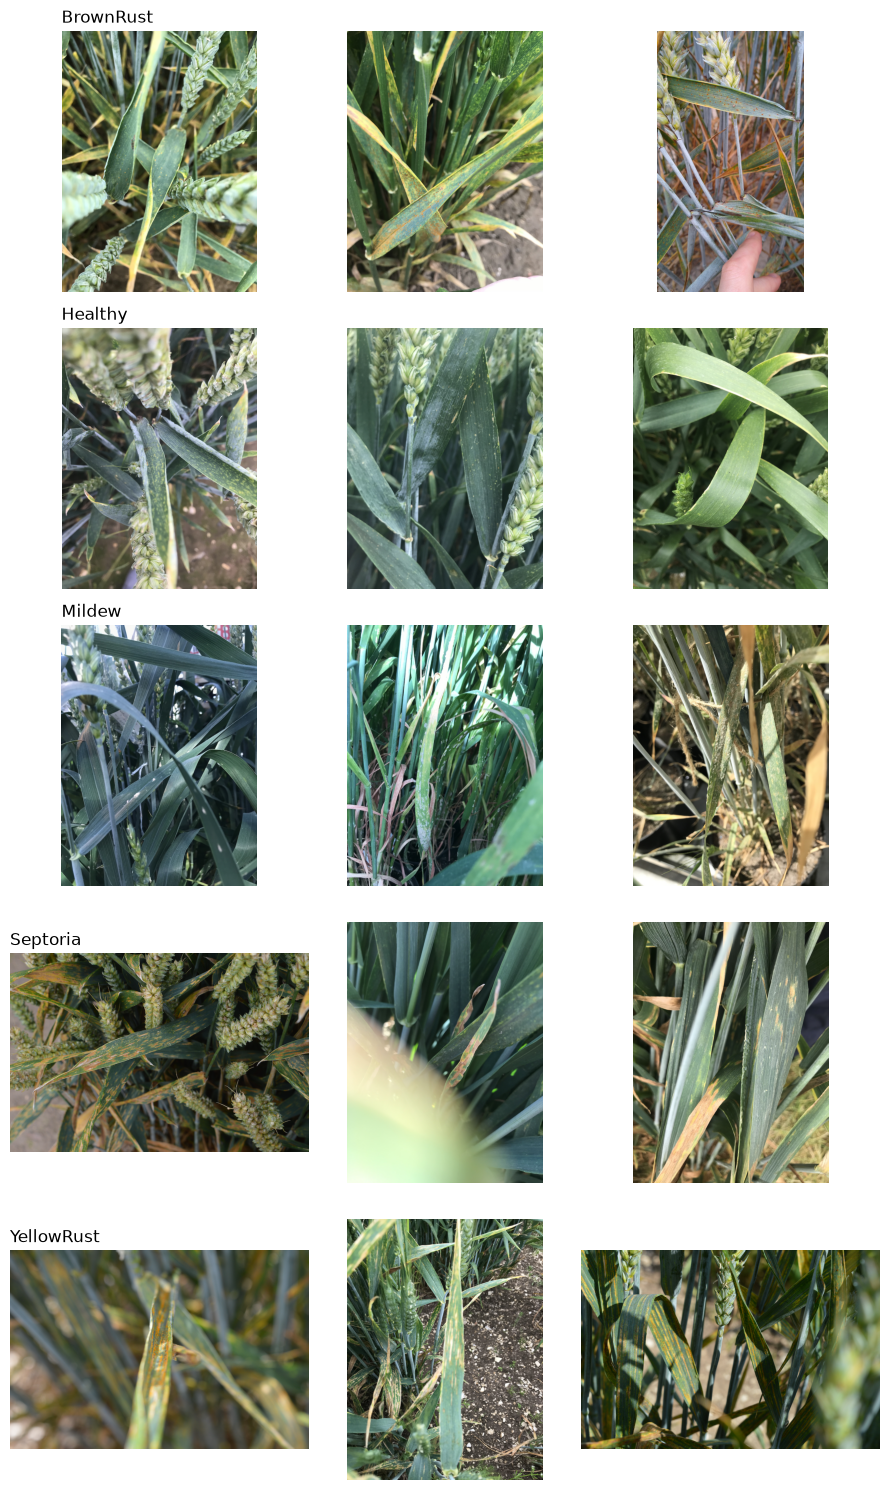

In [6]:
classes = sorted(df["label"].unique())
fig, axes = plt.subplots(len(classes), 3, figsize=(9, 3 * len(classes)))
for i, cls in enumerate(classes):
    samples = df[df["label"] == cls].sample(3, random_state=42)
    for j, p in enumerate(samples["path"]):
        axes[i, j].imshow(Image.open(p))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(cls, loc="left")
plt.tight_layout()
plt.show()

In [7]:
sizes, bad = [], []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            sizes.append(im.size)
    except Exception:
        bad.append(p)

print("Corrupt files:", len(bad))
print(pd.Series(sizes).value_counts().head())

Corrupt files: 0
(709, 945)     396
(567, 756)     203
(709, 471)     192
(738, 491)      77
(567, 1008)     34
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42)

print("train:", len(train_df), "val:", len(val_df), "test:", len(test_df))

splits = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test"),
])
splits.to_csv(r"D:\AgriVision\data\splits.csv", index=False)
print("Saved splits.csv")

train: 699 val: 150 test: 150
Saved splits.csv


In [9]:
import tensorflow as tf

IMG_SIZE = 224
BATCH = 32

classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
print(class_to_idx)

def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def make_ds(frame, shuffle=False):
    paths = frame["path"].values
    labels = frame["label"].map(class_to_idx).values
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(frame), seed=42)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

for x, y in train_ds.take(1):
    print("batch shape:", x.shape, "min/max:", x.numpy().min(), x.numpy().max())

{'BrownRust': 0, 'Healthy': 1, 'Mildew': 2, 'Septoria': 3, 'YellowRust': 4}
batch shape: (32, 224, 224, 3) min/max: 0.0 1.0


In [11]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

y_train = train_df["label"].map(class_to_idx).values
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(1.5533333333333332), 1: np.float64(1.6447058823529412), 2: np.float64(1.2371681415929203), 3: np.float64(0.5729508196721311), 4: np.float64(0.837125748502994)}
